In [ ]:
# Install kagglehub to download Kaggle datasets directly in Colab
!pip install kagglehub -q

# Core data tools
import kagglehub
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

# ML preprocessing and evaluation
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Deep learning
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Dropout, Bidirectional, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

print("All libraries loaded. Let's start!")

All libraries loaded. Let's start!


In [ ]:
# Download KU-HAR dataset via kagglehub
arashnic_har_1_path = kagglehub.dataset_download('arashnic/har-1')
print('Data source import complete.')

# Build path to the raw CSV file (matches dataset folder structure)
CSV_PATH = os.path.join(
    arashnic_har_1_path,
    'Time_domain_subsamples',
    '3.Time_domain_subsamples',
    'KU-HAR_v1.0_raw_samples.csv'
)

# Load the dataset
df = pd.read_csv(CSV_PATH)

# Basic shape check (expected: 9185 samples, 9003 columns)
print(f"Raw dataset shape: {df.shape}")
print(f"First 2 rows, first 3 columns:\n{df.iloc[:2, :3]}")
print(f"Last 3 columns (metadata):\n{df.iloc[:2, 9000:]}")

Using Colab cache for faster access to the 'har-1' dataset.
Data source import complete.
Raw dataset shape: (9184, 9003)
First 2 rows, first 3 columns:
   -0.019247  0.018654  -0.0005703
0   0.009649  0.004752   -0.014206
1  -0.028546 -0.018661    0.005173
Last 3 columns (metadata):
   0.3048  992  1
0       0  992  2
1       0  992  3


In [ ]:
# Extract integer activity labels (column 9000, 0-indexed)
y_raw = df.iloc[:, 9000]
print(f"All unique integer activity IDs: {y_raw.unique()}")

# Our target activity IDs: 0-7 (matches 8 desired activities)
TARGET_IDS = list(range(8))

# Filter rows for target activities
mask = y_raw.isin(TARGET_IDS)
df_filtered = df[mask].copy()

print(f"\nAfter filtering: {len(df_filtered)} samples kept")
print(f"Removed {len(df) - len(df_filtered)} samples from other activities")

# Separate features, labels, and metadata
X_flat = df_filtered.iloc[:, 0:9000].values  # Sensor data: (n_samples, 9000)
y = df_filtered.iloc[:, 9000].values  # Integer labels: 0-7
seq_lens = df_filtered.iloc[:, 9001]  # True signal lengths
sample_ids = df_filtered.iloc[:, 9002]  # Sample IDs

print(f"Filtered X shape: {X_flat.shape}, y shape: {y.shape}")

# Map integer IDs to readable activity names for later
id_to_activity = {
    0: 'walk', 1: 'run', 2: 'stair up', 3: 'stair down',
    4: 'sit', 5: 'stand', 6: 'lay', 7: 'jump'
}

All unique integer activity IDs: [ 0  1  2  3  4  5  6  7  8 10  9 11 12 13 14 15 16 17]

After filtering: 4920 samples kept
Removed 4264 samples from other activities
Filtered X shape: (4920, 9000), y shape: (4920,)



Class distribution (ID: count):
0 (walk): 595
1 (run): 596
2 (stair up): 579
3 (stair down): 594
4 (sit): 791
5 (stand): 588
6 (lay): 543
7 (jump): 634


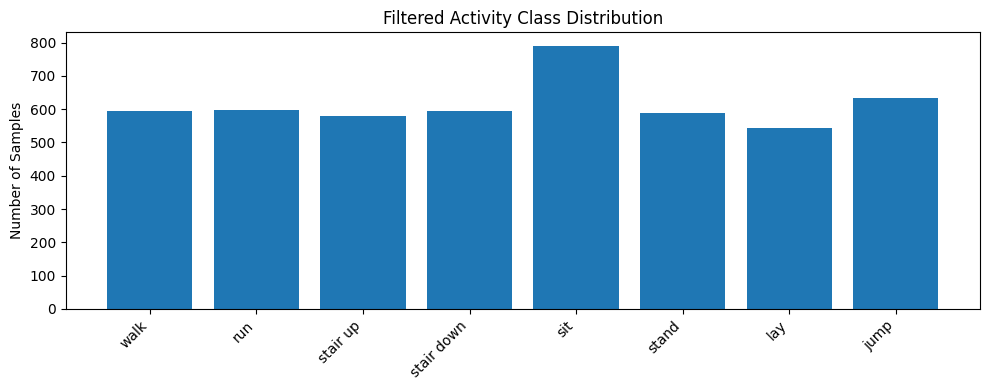

In [ ]:
# Count samples per activity
class_counts = pd.Series(y).value_counts().sort_index()
print("\nClass distribution (ID: count):")
for id, count in class_counts.items():
    print(f"{id} ({id_to_activity[id]}): {count}")

# Plot distribution
plt.figure(figsize=(10, 4))
plt.bar(class_counts.index, class_counts.values)
plt.xticks(range(8), id_to_activity.values(), rotation=45, ha='right')
plt.ylabel('Number of Samples')
plt.title('Filtered Activity Class Distribution')
plt.tight_layout()
plt.show()

In [ ]:
n_samples = X_flat.shape[0]
n_timesteps = 1500
n_channels = 6

# Initialize 3D array: (samples, 1500, 6)
X_reshaped = np.zeros((n_samples, n_timesteps, n_channels))

# Split each channel's 1500 columns and assign to the channel axis
for ch in range(n_channels):
    start_col = ch * n_timesteps
    end_col = (ch + 1) * n_timesteps
    X_reshaped[:, :, ch] = X_flat[:, start_col:end_col]

# Shape checks
print(f"Reshaped X shape: {X_reshaped.shape}")  # Expected: (n_samples, 1500, 6)
print(f"Single sample shape: {X_reshaped[0].shape}")  # Expected: (1500, 6)

# Sanity check: first timestep matches raw CSV
print(f"\nSample 0, timestep 0 (ax, ay, az, gx, gy, gz): {X_reshaped[0, 0, :]}")
print(f"Raw CSV first value (ax at t=0): {X_flat[0, 0]}")

Reshaped X shape: (4920, 1500, 6)
Single sample shape: (1500, 6)

Sample 0, timestep 0 (ax, ay, az, gx, gy, gz): [ 0.0096493 -0.0075748  0.027414  -0.017926   0.012367  -0.0059322]
Raw CSV first value (ax at t=0): 0.0096493


In [ ]:
# Split 80% train, 20% test, stratify by labels to preserve class balance
X_train, X_test, y_train, y_test, seq_train, seq_test = train_test_split(
    X_reshaped, y, seq_lens,
    test_size=0.2,
    stratify=y,
    random_state=42  # Reproducibility seed
)

print(f"Train samples: {len(X_train)}, Test samples: {len(X_test)}")
print(f"Train class distribution:\n{pd.Series(y_train).value_counts().sort_index()}")
print(f"Test class distribution:\n{pd.Series(y_test).value_counts().sort_index()}")

Train samples: 3936, Test samples: 984
Train class distribution:
0    476
1    477
2    463
3    475
4    633
5    470
6    435
7    507
Name: count, dtype: int64
Test class distribution:
0    119
1    119
2    116
3    119
4    158
5    118
6    108
7    127
Name: count, dtype: int64


In [ ]:
def apply_sliding_window(X, seq_lens, window_size=300, stride=150, labels=None):
    """
    Generate overlapping windows from 1500-timestep samples.
    Truncates to true signal length to avoid zero-padded parts.
    """
    windows = []
    window_labels = []

    for i in range(len(X)):
        # Truncate sample to its true signal length (ignore zero padding)
        x = X[i, :seq_lens.iloc[i], :]
        if len(x) < window_size:
            continue  # Skip samples shorter than window size

        # Generate windows with stride
        for start in range(0, len(x) - window_size + 1, stride):
            window = x[start:start+window_size, :]
            windows.append(window)
            window_labels.append(labels[i] if labels is not None else y_train[i])

    return np.array(windows), np.array(window_labels)

# Window parameters (light, not aggressive)
window_size = 300
stride = 75

print("Generating training windows...")
X_train_win, y_train_win = apply_sliding_window(
    X_train, seq_train, window_size, stride, y_train
)
print(f"Train windows shape: {X_train_win.shape}")  # (n_windows, 300, 6)

print("\nGenerating test windows...")
X_test_win, y_test_win = apply_sliding_window(
    X_test, seq_test, window_size, stride, y_test
)
print(f"Test windows shape: {X_test_win.shape}")

print(f"\nApprox windows per train sample: {len(X_train_win)/len(X_train):.1f}")

Generating training windows...
Train windows shape: (37651, 300, 6)

Generating test windows...
Test windows shape: (9397, 300, 6)

Approx windows per train sample: 9.6


In [ ]:
scaler = StandardScaler()

# Flatten 3D windows to 2D (n_windows * window_size, 6) to fit scaler
X_train_flat = X_train_win.reshape(-1, X_train_win.shape[-1])
scaler.fit(X_train_flat)  # Only fit on training data!

# Transform train and test windows, reshape back to 3D
X_train_norm = scaler.transform(X_train_flat).reshape(X_train_win.shape)
X_test_flat = X_test_win.reshape(-1, X_test_win.shape[-1])
X_test_norm = scaler.transform(X_test_flat).reshape(X_test_win.shape)

# Sanity check: means ~0, stds ~1
print(f"Normalized train shape: {X_train_norm.shape}")
print(f"Channel means (should be ~0): {X_train_norm.mean(axis=(0,1))}")
print(f"Channel stds (should be ~1): {X_train_norm.std(axis=(0,1))}")

Normalized train shape: (37651, 300, 6)
Channel means (should be ~0): [-2.86054793e-15 -1.49834098e-14  1.02983071e-14  1.68049315e-14
  2.84373131e-16 -3.62135814e-15]
Channel stds (should be ~1): [1. 1. 1. 1. 1. 1.]


In [ ]:
model = Sequential([
    # First Conv1D: 32 filters, look at 3 consecutive timesteps
    Conv1D(64, kernel_size=3, activation='relu', input_shape=(window_size, n_channels)),
    MaxPooling1D(pool_size=2),  # 300 → 149 timesteps

    # Second Conv1D: 64 filters for more complex patterns
    Conv1D(128, kernel_size=3, activation='relu'),
    MaxPooling1D(pool_size=2),  # 149 → 74 timesteps

    # Dropout(0.2),  # Prevent overfitting

    # BiLSTM: 64 units, process sequence forward and backward
    Bidirectional(LSTM(32, return_sequences=False)),

    # Classification head
    Dense(32, activation='relu'),
    Dense(8, activation='softmax')  # 8 activity classes
])

print("Model summary:")
model.summary()

Model summary:


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 298, 64)        │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 149, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 147, 128)       │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 73, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           264 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 69,480 (271.41 KB)

 Trainable params: 69,480 (271.41 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='RMSprop',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
print("Model compiled. Ready to train.")

Model compiled. Ready to train.


In [ ]:
# early_stop = EarlyStopping(
#     monitor='val_loss',
#     patience=5,
#     restore_best_weights=True,
#     verbose=1
# )

print("Starting training...")
history = model.fit(
    X_train_norm, y_train_win,
    epochs=25,
    batch_size=32,
    validation_split=0.2,  # Use 20% of training data for validation
    # callbacks=[early_stop],
    verbose=1
)
print("Training complete.")

Starting training...
Epoch 1/25
942/942 ━━━━━━━━━━━━━━━━━━━━ 103s 109ms/step - accuracy: 0.9865 - loss: 0.0424 - val_accuracy: 0.9668 - val_loss: 0.1337
Epoch 2/25
942/942 ━━━━━━━━━━━━━━━━━━━━ 95s 101ms/step - accuracy: 0.9861 - loss: 0.0422 - val_accuracy: 0.9757 - val_loss: 0.1093
Epoch 3/25
942/942 ━━━━━━━━━━━━━━━━━━━━ 95s 101ms/step - accuracy: 0.9863 - loss: 0.0448 - val_accuracy: 0.9748 - val_loss: 0.1065
Epoch 4/25
942/942 ━━━━━━━━━━━━━━━━━━━━ 100s 106ms/step - accuracy: 0.9872 - loss: 0.0413 - val_accuracy: 0.9761 - val_loss: 0.0935
Epoch 5/25
942/942 ━━━━━━━━━━━━━━━━━━━━ 94s 100ms/step - accuracy: 0.9866 - loss: 0.0407 - val_accuracy: 0.9793 - val_loss: 0.0900
Epoch 6/25
942/942 ━━━━━━━━━━━━━━━━━━━━ 95s 101ms/step - accuracy: 0.9877 - loss: 0.0369 - val_accuracy: 0.9746 - val_loss: 0.0999
Epoch 7/25
942/942 ━━━━━━━━━━━━━━━━━━━━ 142s 101ms/step - accuracy: 0.9881 - loss: 0.0380 - val_accuracy: 0.9627 - val_loss: 0.1829
Epoch 8/25
942/942 ━━━━━━━━━━━━━━━━━━━━ 95s 101ms/step - ac

In [ ]:
best_epoch = np.argmax(history.history['val_accuracy']) + 1
best_val_acc = max(history.history['val_accuracy'])

print("Best Epoch:", best_epoch)
print("Best Validation Accuracy:", best_val_acc)

Best Epoch: 20
Best Validation Accuracy: 0.9822068810462952


Test accuracy: 0.9749
Test loss: 0.1352


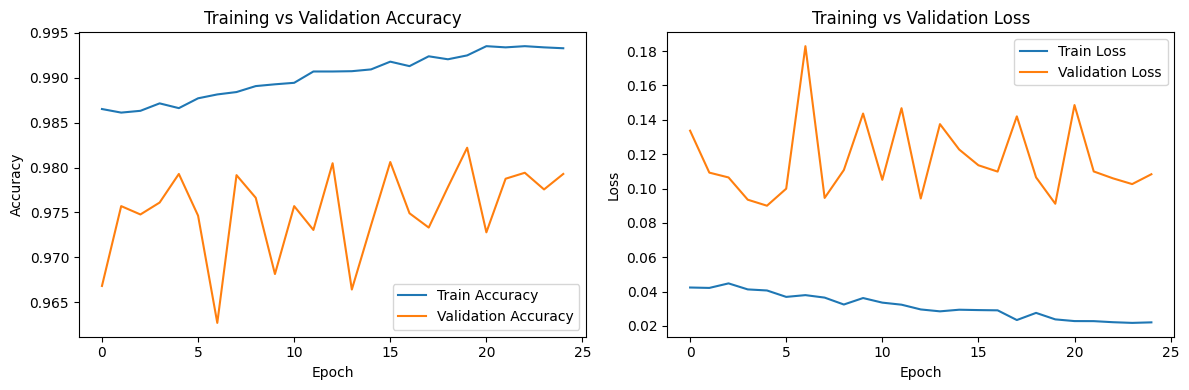

Confusion Matrix (rows=true label, cols=predicted label):
[[1165   19   20    1    0    7    0    0]
 [  20 1162   32    0    0    6    0    0]
 [   7   21 1125    5    2    4    8    0]
 [   1    0   10 1209    0    0    2    3]
 [   0    0    2    0 1430    0    1    8]
 [  11    2   13    0    0 1156    0    0]
 [   0    0    1    5    2    0 1140   11]
 [   0    0    0    1    3    0    8  774]]

Classification Report:
              precision    recall  f1-score   support

        walk       0.97      0.96      0.96      1212
         run       0.97      0.95      0.96      1220
    stair up       0.94      0.96      0.95      1172
  stair down       0.99      0.99      0.99      1225
         sit       1.00      0.99      0.99      1441
       stand       0.99      0.98      0.98      1182
         lay       0.98      0.98      0.98      1159
        jump       0.97      0.98      0.98       786

    accuracy                           0.97      9397
   macro avg       0.97      0.

In [ ]:
# Test accuracy and loss
test_loss, test_acc = model.evaluate(X_test_norm, y_test_win, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")

# Plot training history
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training vs Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Training vs Validation Loss')
plt.tight_layout()
plt.show()

# Predictions on test set
y_pred = model.predict(X_test_norm, verbose=0).argmax(axis=1)

# Confusion matrix
print("Confusion Matrix (rows=true label, cols=predicted label):")
print(confusion_matrix(y_test_win, y_pred))

# Classification report (precision, recall, F1-score)
print("\nClassification Report:")
print(classification_report(
    y_test_win, y_pred,
    target_names=id_to_activity.values()
))